# ML - Wine Quality

It does not require GPU access to run this notebook.

This notebook is authored by [Anmol Talwar](https://www.linkedin.com/in/anmol-talwar-922061164/) - Founder and Trainer at Talent Catalyst AI

Visit the blogs on [Talent Catalyst AI](https://talentcatalystai.com/) to learn more on New Gen Technology

In [2]:
#Importing the Required Libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb
from sklearn.svm import SVC

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

In [3]:
#Loading the Dataset

df = pd.read_csv("winequalityN.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'winequalityN.csv'

In [ ]:
df.head()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [ ]:
len(df.columns)

13

In [ ]:
#Segregating the Numerical and Categorical Columns

Numercial_cols = list(df.columns)[1:]
numerical_vars = df.columns.drop(['quality', 'type'])

# EDA

In [ ]:
#Get the data types of each Variable

df.dtypes

,0
type,object
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64


In [ ]:
# Count of each Category in the Categorical Variable

df['quality'].value_counts()

,count
quality,
6,2836
5,2138
7,1079
4,216
8,193
3,30
9,5


In [ ]:
# Percentage (Normalized Count) of each Category in the Categorical Variable

df['quality'].value_counts(normalize=True)*100

,proportion
quality,
6,43.650916
5,32.907496
7,16.607665
4,3.324611
8,2.970602
3,0.461752
9,0.076959


In [ ]:
df['type'].value_counts(normalize=True)*100

,proportion
type,
white,75.388641
red,24.611359


In [ ]:
#Stats for the Numerical Variables

df[numerical_vars].describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
count,6487.000000,6489.000000,6494.000000,6495.000000,6495.000000,6497.000000,6497.000000,6497.000000,6488.000000,6493.000000,6497.000000
mean,7.216579,0.339691,0.318722,5.444326,0.056042,30.525319,115.744574,0.994697,3.218395,0.531215,10.491801
std,1.296750,0.164649,0.145265,4.758125,0.035036,17.749400,56.521855,0.002999,0.160748,0.148814,1.192712
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000


In [ ]:
#check for NaN values in each column
df.isnull().sum()

,0
type,0
fixed acidity,10
volatile acidity,8
citric acid,3
residual sugar,2
chlorides,2
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,9


***Line Graph***

This plot visualizes the median of each chemical property across different quality levels, helping to observe any trends between the chemical properties and wine quality.

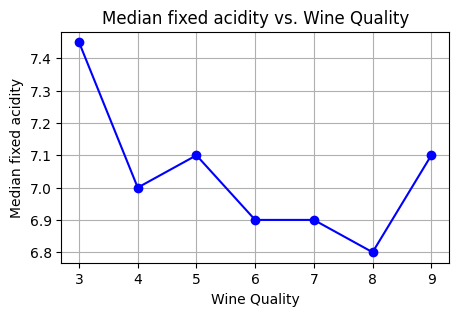

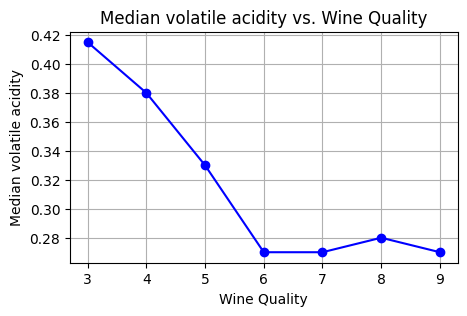

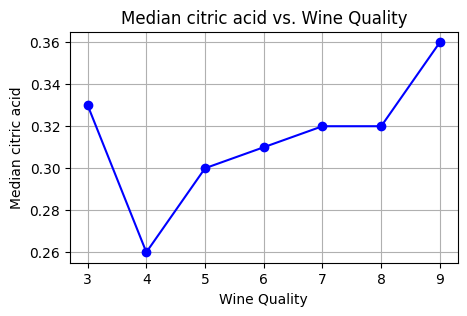

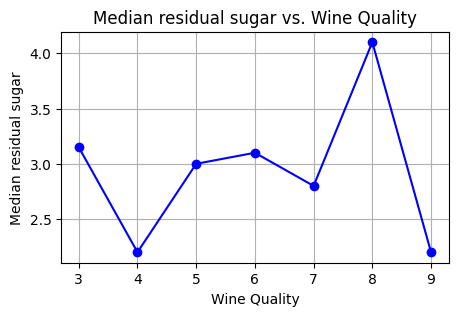

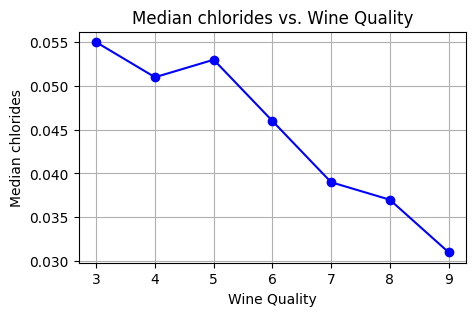

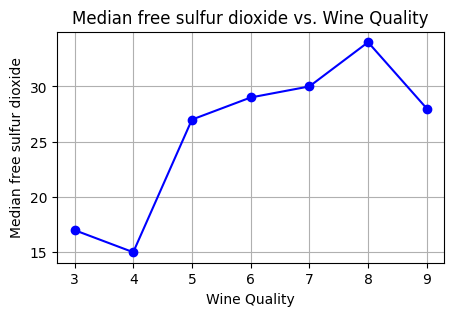

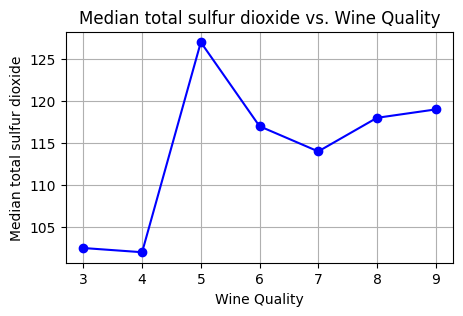

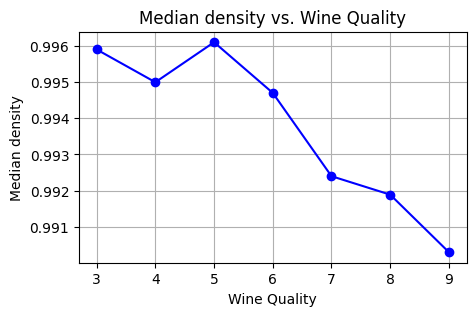

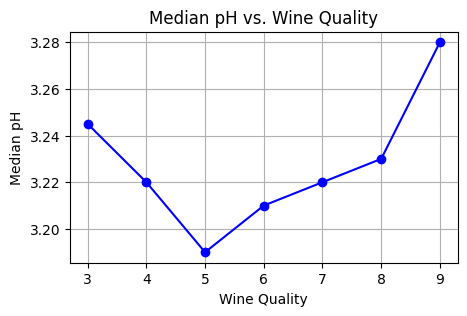

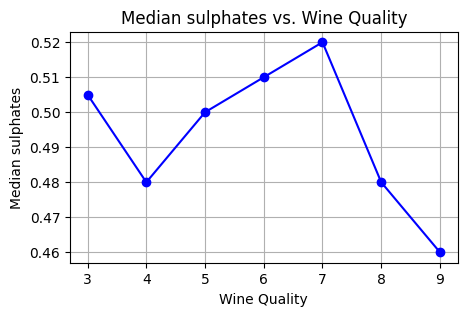

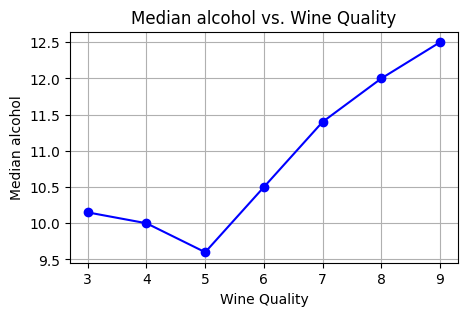

In [ ]:
# Individual Line Graphs - Quality vs. Median of Each Numerical Variable

median_values = df[Numercial_cols].groupby('quality').median()
for var in numerical_vars:
    plt.figure(figsize=(5, 3))
    plt.plot(median_values.index, median_values[var], marker='o', linestyle='-', color='b')
    plt.title(f'Median {var} vs. Wine Quality')
    plt.xlabel('Wine Quality')
    plt.ylabel(f'Median {var}')
    plt.grid(True)
    plt.show()

***Bar Graph***

The bar graph shows the percentage distribution of wines for each quality rating, giving insight into the distribution of wine quality in the dataset.

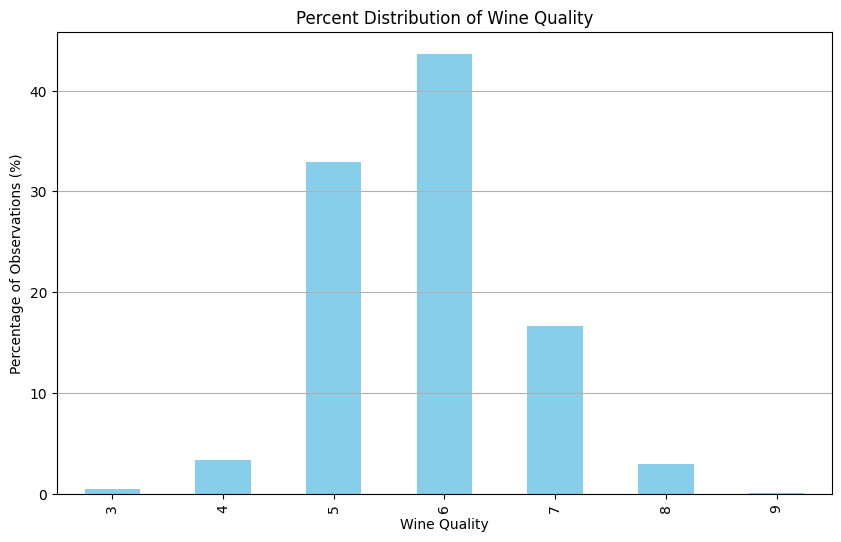

In [ ]:
quality_counts = df['quality'].value_counts(normalize=True) * 100
quality_counts.sort_index().plot(kind='bar', color='skyblue', figsize=(10, 6))
plt.title('Percent Distribution of Wine Quality')
plt.xlabel('Wine Quality')
plt.ylabel('Percentage of Observations (%)')
plt.grid(axis='y')
plt.show()

***Pie Chart***

The pie chart compares the percentage of red and white wine records, providing a quick visual understanding of the proportion of each wine type in the dataset.

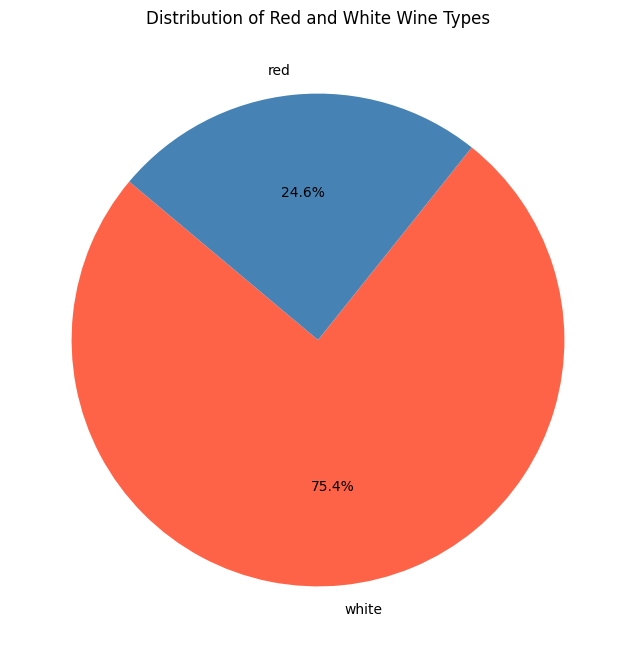

In [ ]:
type_counts = df['type'].value_counts(normalize=True) * 100
type_counts.plot(kind='pie', autopct='%1.1f%%', colors=['#FF6347', '#4682B4'], figsize=(8, 8), startangle=140)
plt.title('Distribution of Red and White Wine Types')
plt.ylabel('')  # Hide the y-label
plt.show()

***Correlation Matrix***

The correlation matrix shows the Pearson correlation coefficients between numerical variables, helping to identify relationships between features.

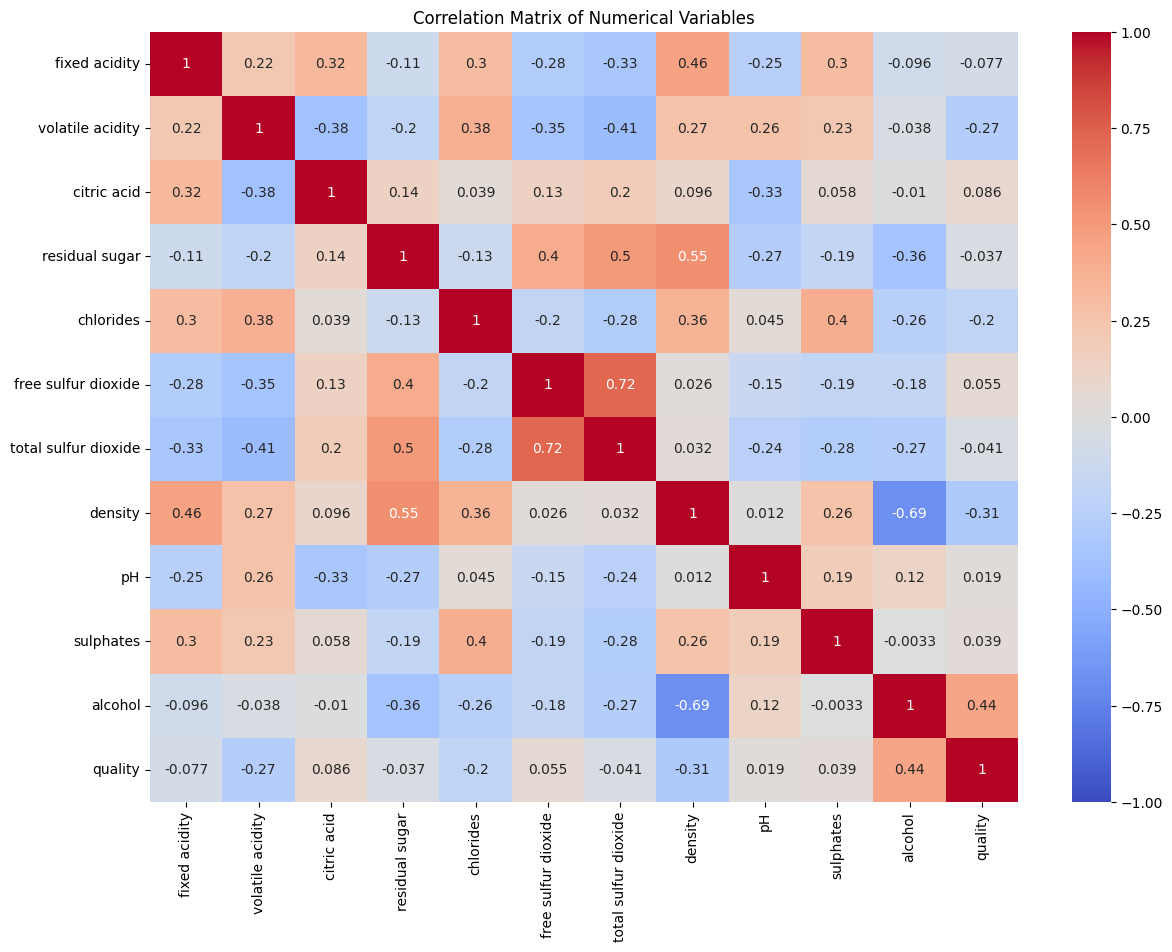

In [ ]:
plt.figure(figsize=(14, 10))
corr_matrix = df[Numercial_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numerical Variables')
plt.show()

***Box Plots***

The box plots for each numerical variable show the distribution, central tendency, and outliers, which can help in understanding the spread and any potential anomalies in the data.

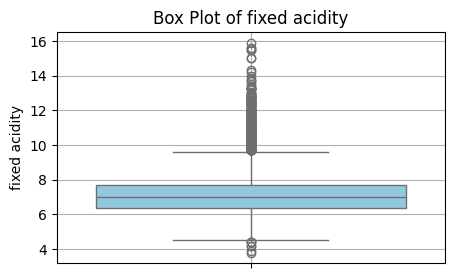

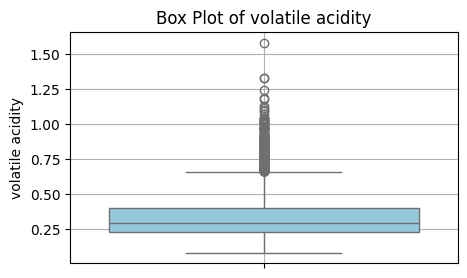

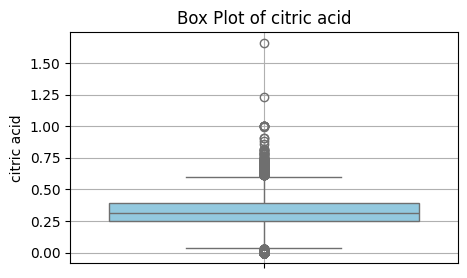

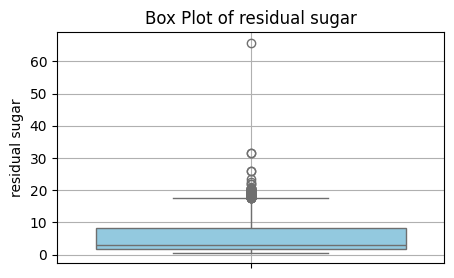

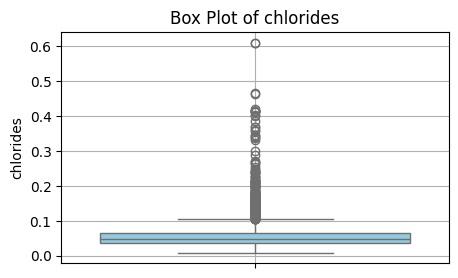

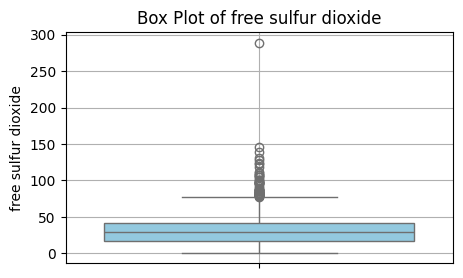

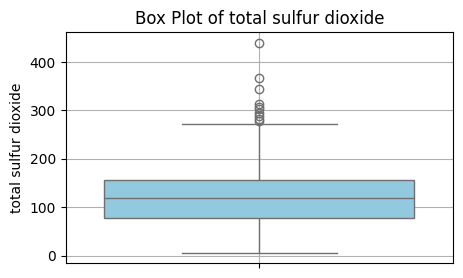

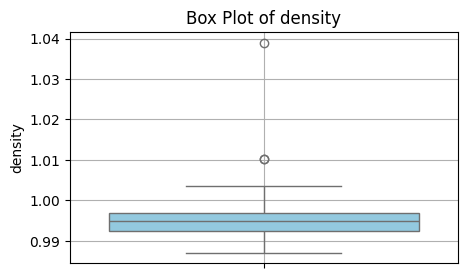

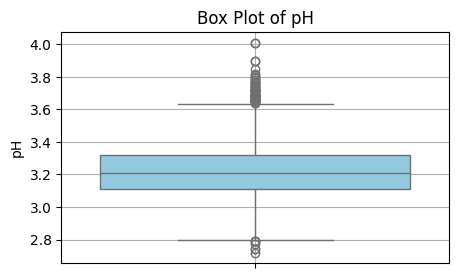

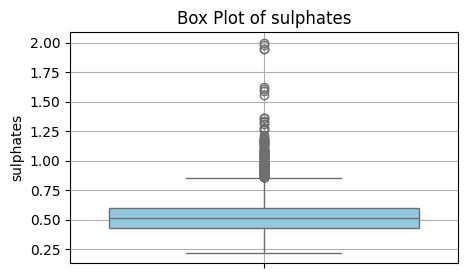

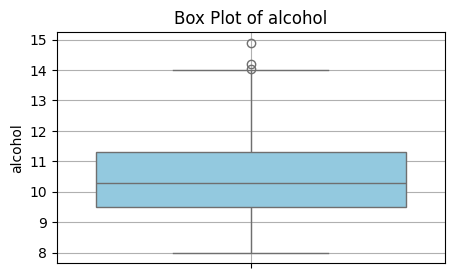

In [ ]:
for var in numerical_vars:
    plt.figure(figsize=(5,3))
    sns.boxplot(y=var, data=df, color='skyblue')
    plt.title(f'Box Plot of {var}')
    plt.grid(True)
    plt.show()

***Violin Plots***

•	 **Purpose**: Compare the distribution of numerical variables across different categories (e.g., wine types or quality levels).

•	 **Insight**: Provides a richer understanding of the distribution of each feature across different wine quality levels, capturing both the distribution and density.

<ipython-input-17-a3dbedc35940>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='quality', y=var, data=df, palette='muted')


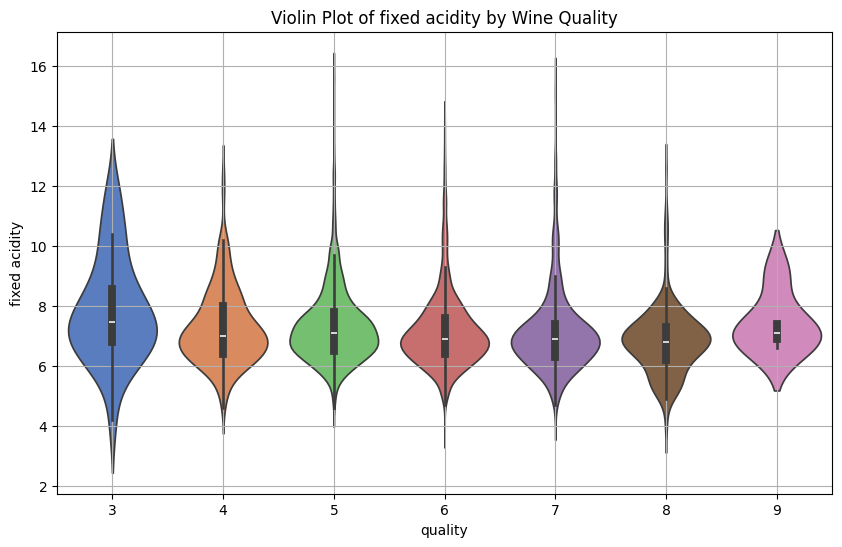

<ipython-input-17-a3dbedc35940>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='quality', y=var, data=df, palette='muted')


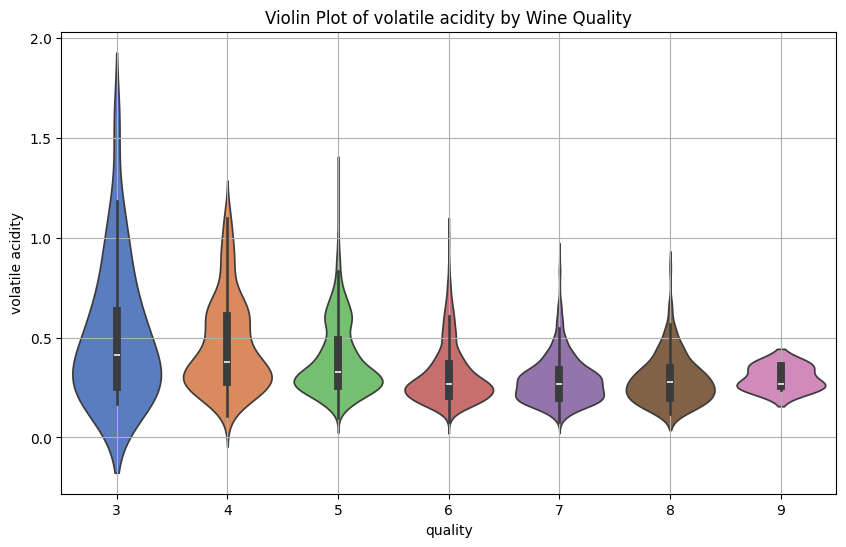

<ipython-input-17-a3dbedc35940>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='quality', y=var, data=df, palette='muted')


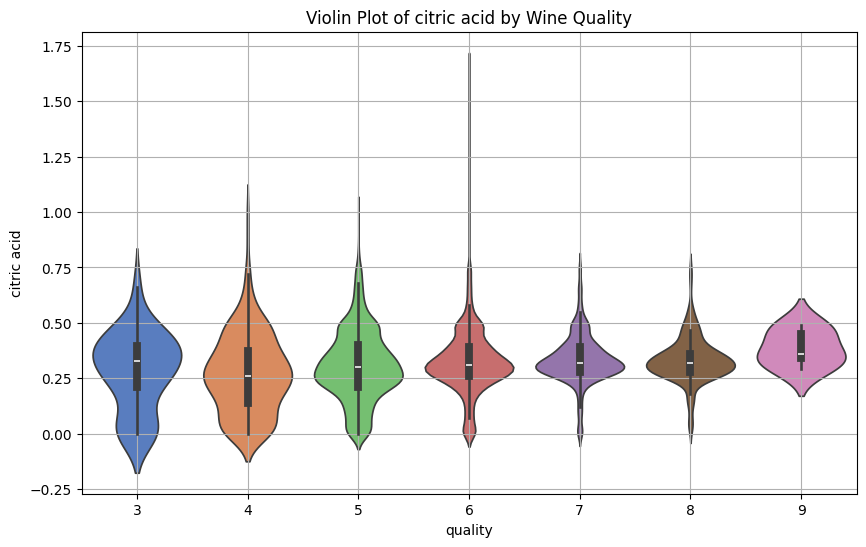

<ipython-input-17-a3dbedc35940>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='quality', y=var, data=df, palette='muted')


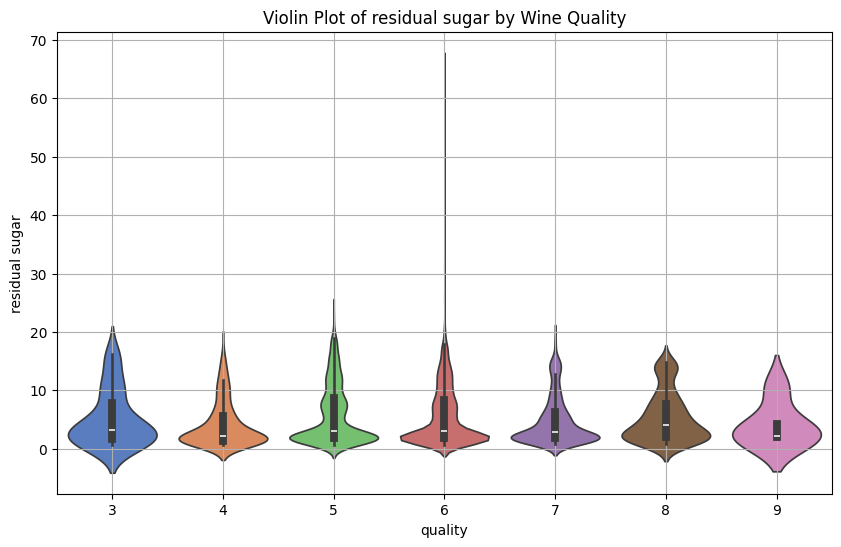

<ipython-input-17-a3dbedc35940>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='quality', y=var, data=df, palette='muted')


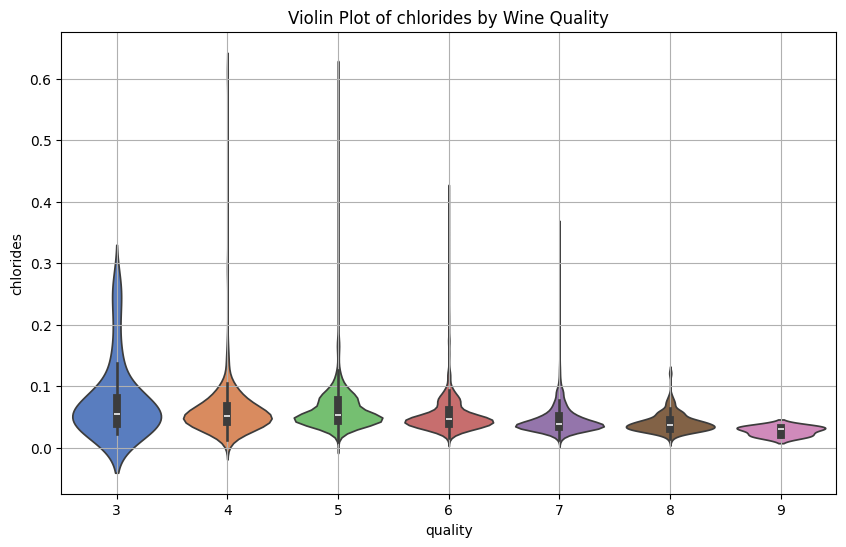

<ipython-input-17-a3dbedc35940>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='quality', y=var, data=df, palette='muted')


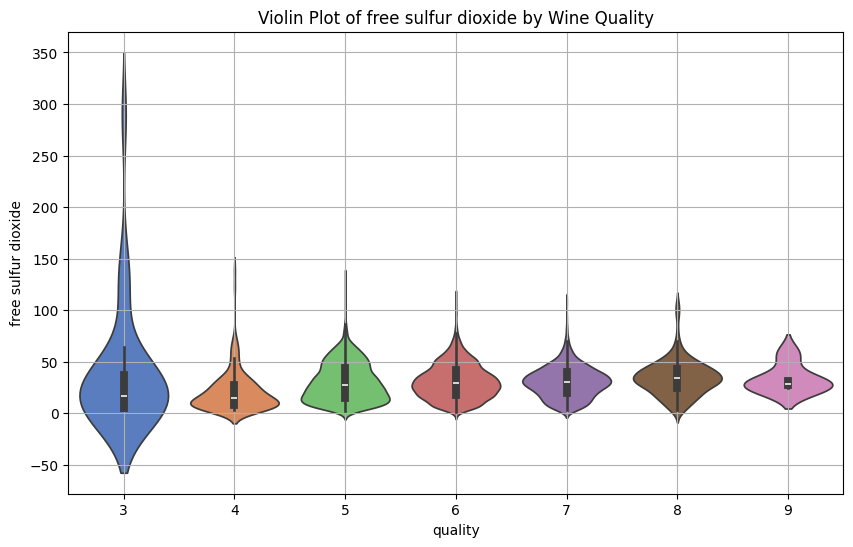

<ipython-input-17-a3dbedc35940>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='quality', y=var, data=df, palette='muted')


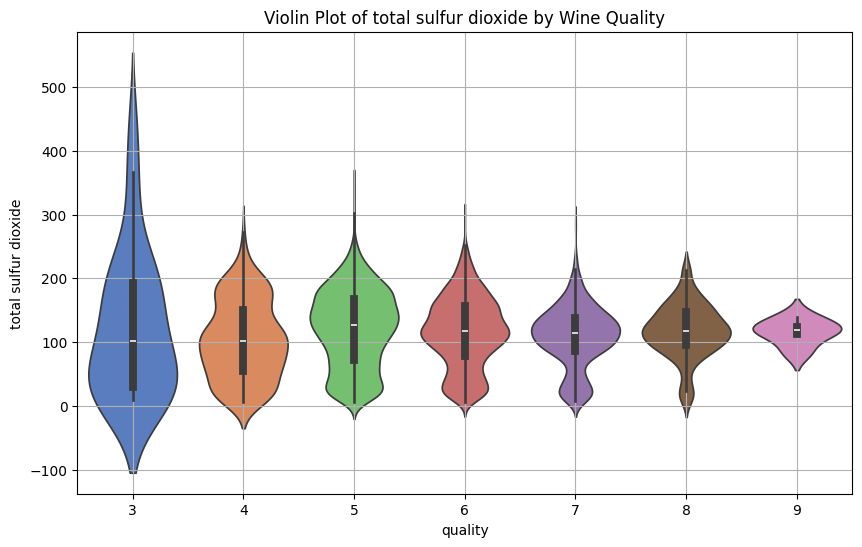

<ipython-input-17-a3dbedc35940>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='quality', y=var, data=df, palette='muted')


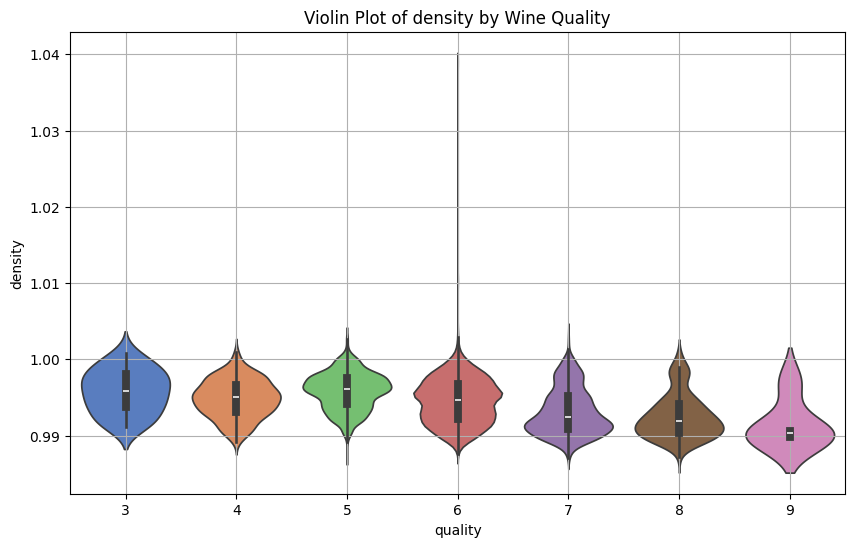

<ipython-input-17-a3dbedc35940>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='quality', y=var, data=df, palette='muted')


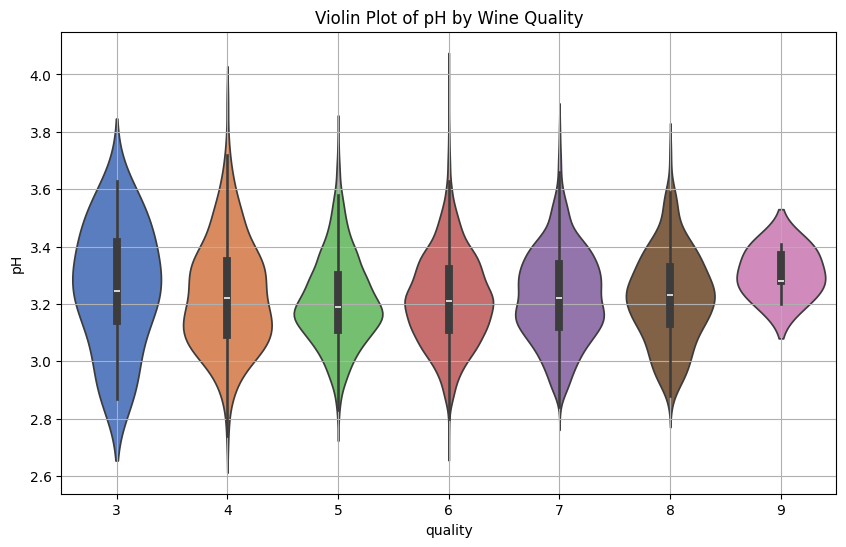

<ipython-input-17-a3dbedc35940>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='quality', y=var, data=df, palette='muted')


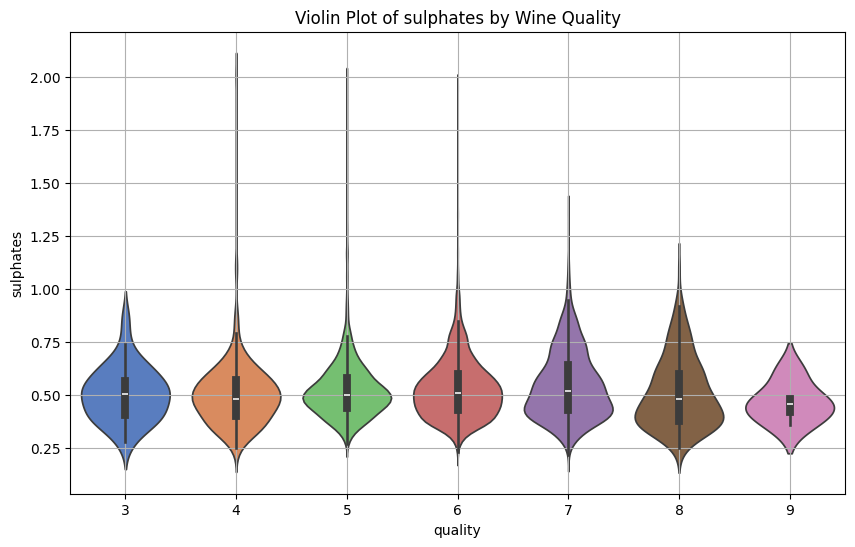

<ipython-input-17-a3dbedc35940>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='quality', y=var, data=df, palette='muted')


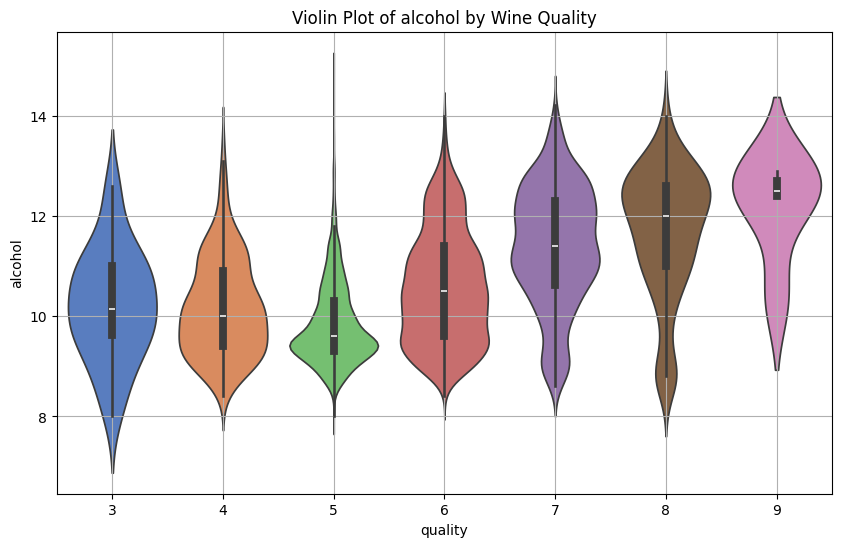

In [ ]:
for var in numerical_vars:
    plt.figure(figsize=(10, 6))
    sns.violinplot(x='quality', y=var, data=df, palette='muted')
    plt.title(f'Violin Plot of {var} by Wine Quality')
    plt.grid(True)
    plt.show()

# Clustering
**to Reduce the Number of Classes**

In [ ]:
df_cluster = df.copy()

# Convert categorical variable 'type' to numerical
df_cluster['type'] = df_cluster['type'].map({'red': 1, 'white': 0})

# Handle NaN values: Fill missing values with the median of each column
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(imputer.fit_transform(df_cluster), columns=df_cluster.columns)


# Separate features (excluding the target variable 'quality')
features = df_imputed.drop(['quality'], axis=1)
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

**Clustering without PCA**

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


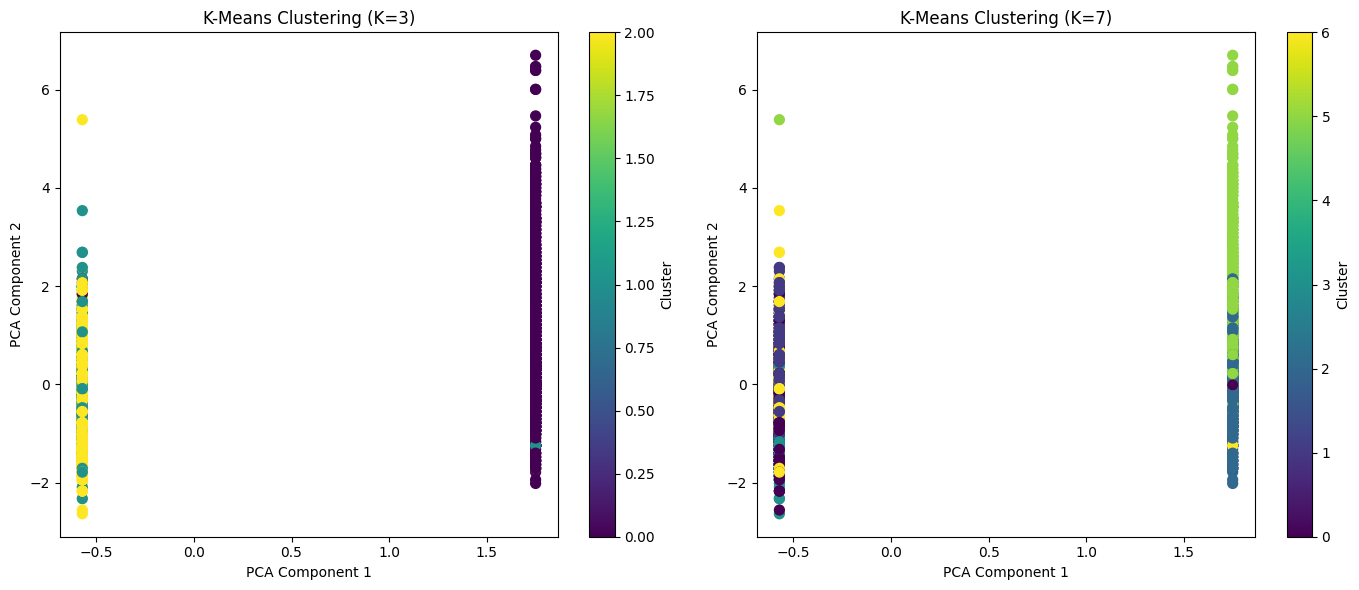

In [ ]:
# Perform K-Means clustering for K=3
kmeans_3 = KMeans(n_clusters=3, random_state=42)
clusters_3 = kmeans_3.fit_predict(features_scaled)

# Perform K-Means clustering for K=7
kmeans_7 = KMeans(n_clusters=7, random_state=42)
clusters_7 = kmeans_7.fit_predict(features_scaled)

# Plot for K=3
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
scatter = plt.scatter(features_scaled[:, 0], features_scaled[:, 1], c=clusters_3, cmap='viridis', s=50)
plt.title('K-Means Clustering (K=3)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(scatter, label='Cluster')

# Plot for K=7
plt.subplot(1, 2, 2)
scatter = plt.scatter(features_scaled[:, 0], features_scaled[:, 1], c=clusters_7, cmap='viridis', s=50)
plt.title('K-Means Clustering (K=7)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(scatter, label='Cluster')

plt.tight_layout()
plt.show()

**Clustering with PCA**

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


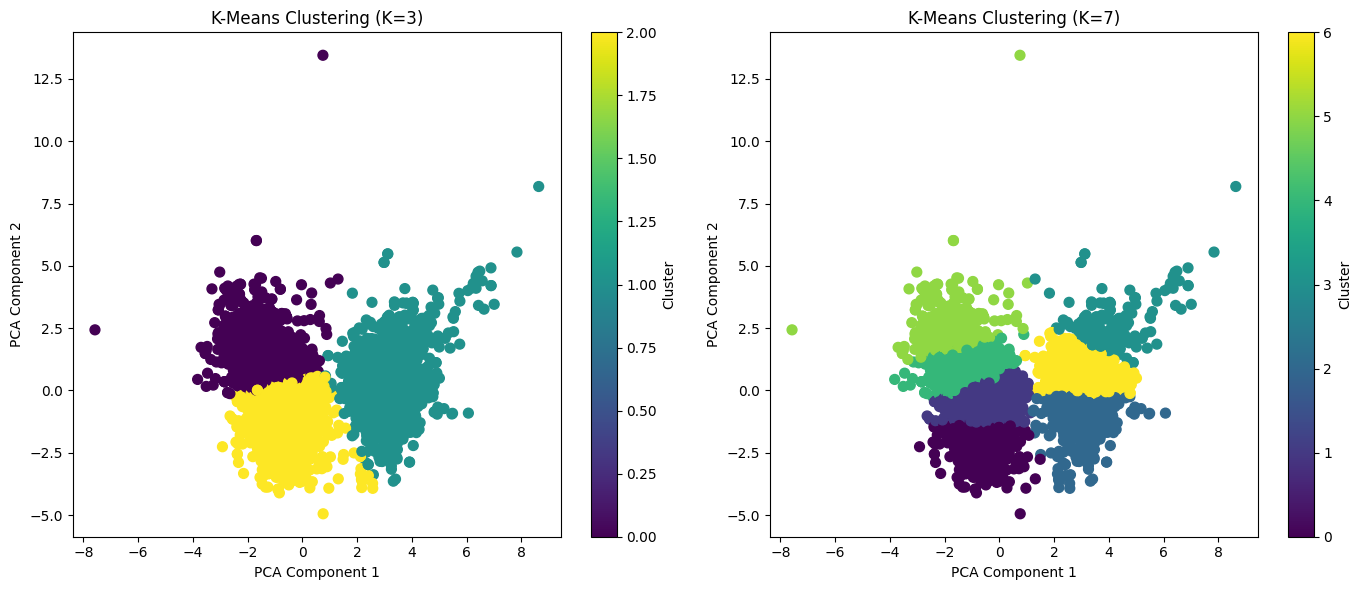

In [ ]:
# Dimensionality Reduction using PCA
pca = PCA(n_components=2)
features_pca = pca.fit_transform(features_scaled)

# Perform K-Means clustering for K=3
kmeans_3 = KMeans(n_clusters=3, random_state=42)
clusters_3 = kmeans_3.fit_predict(features_pca)

# Perform K-Means clustering for K=7
kmeans_7 = KMeans(n_clusters=7, random_state=42)
clusters_7 = kmeans_7.fit_predict(features_pca)

# Plot for K=3
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
scatter = plt.scatter(features_pca[:, 0], features_pca[:, 1], c=clusters_3, cmap='viridis', s=50)
plt.title('K-Means Clustering (K=3)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(scatter, label='Cluster')

# Plot for K=7
plt.subplot(1, 2, 2)
scatter = plt.scatter(features_pca[:, 0], features_pca[:, 1], c=clusters_7, cmap='viridis', s=50)
plt.title('K-Means Clustering (K=7)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(scatter, label='Cluster')

plt.tight_layout()
plt.show()


# Preprocessing

In [ ]:
df_model= df.copy()

# Convert categorical variable 'type' to numerical
df_model['type'] = df_model['type'].map({'red': 1, 'white': 0})

# Handle NaN values: Fill missing values with the median of each column
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(imputer.fit_transform(df_model), columns=df_model.columns)

# Map the quality to new classes
def map_quality(q):
    if q in [3, 4, 5]:
        return 0
    elif q == 6:
        return 1
    elif q in [7, 8, 9]:
        return 2

df_imputed['quality_class'] = df_imputed['quality'].apply(map_quality)

# Outlier Treatment
def remove_outliers(df, features):
    for feature in features:
        Q1 = df[feature].quantile(0.25)
        Q3 = df[feature].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df = df[(df[feature] >= lower_bound) & (df[feature] <= upper_bound)]
    return df

# Separate features and target
features = df_imputed.drop(['quality', 'quality_class'], axis=1)
target = df_imputed['quality_class']

# Remove outliers only for features except 'type'
features_no_outliers = remove_outliers(df_imputed, features.columns.difference(['type']))
print(features_no_outliers.columns)

# Separate features and target again after outlier removal
features_no_outliers = features_no_outliers.drop(['quality', 'quality_class'], axis=1)
target_no_outliers = df_imputed.loc[features_no_outliers.index, 'quality_class']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(features_no_outliers, target_no_outliers, test_size=0.3, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Index(['type', 'fixed acidity', 'volatile acidity', 'citric acid',
       'residual sugar', 'chlorides', 'free sulfur dioxide',
       'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol',
       'quality', 'quality_class'],
      dtype='object')


# Modelling

In [ ]:
# Initialize and train models
models = {
    'XGBoost' : xgb.XGBClassifier(),
    'LightGBM': lgb.LGBMClassifier(),
    'Random Forest': RandomForestClassifier(),
    'SVC': SVC()
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = {
        'Accuracy': accuracy,
        'Classification Report': classification_report(y_test, y_pred)
    }

# Print results
for name, metrics in results.items():
    print(f"Model: {name}")
    print(f"Accuracy: {metrics['Accuracy']:.4f}")
    print("Classification Report:")
    print(metrics['Classification Report'])


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000623 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1206
[LightGBM] [Info] Number of data points in the train set: 3371, number of used features: 12
[LightGBM] [Info] Start training from score -1.159775
[LightGBM] [Info] Start training from score -0.773734
[LightGBM] [Info] Start training from score -1.490963
Model: XGBoost
Accuracy: 0.6750
Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.67      0.69       488
           1       0.64      0.69      0.66       641
           2       0.70      0.65      0.68       317

    accuracy                           0.67      1446
   macro avg       0.68      0.67      0.68      1446
weighted avg       0.68      0.67      0.68      1446

Model: LightGBM
Accuracy: 0.6867
Classification Report:
              precision    recall  f1-score   support

   

**HyperParameter Tuning**



1.   **n_estimators**: Number of trees in the forest.
2.   **max_depth**: Maximum depth of each tree.
3.   **min_samples_split**: Minimum number of samples required to split an internal node.
4.   **min_samples_leaf**: Minimum number of samples required to be at a leaf node.
5.  **max_features**: Number of features to consider when looking for the best split.


In [ ]:
%%time

from sklearn.model_selection import GridSearchCV

# Initialize Random Forest
rf = RandomForestClassifier(random_state=42)

# Define the parameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 6, 10],
    'min_samples_leaf': [2, 4]
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=2, scoring='accuracy', n_jobs=-1, verbose=2)

# Fit GridSearchCV
grid_search.fit(X_train_scaled, y_train)

# Get the best model and parameters
best_rf = grid_search.best_estimator_
best_params = grid_search.best_params_

# Predict and evaluate the best model
y_pred = best_rf.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"Best Parameters: {best_params}")
print(f"Accuracy: {accuracy:.4f}")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Fitting 2 folds for each of 54 candidates, totalling 108 fits
Best Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Accuracy: 0.7040
Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.67      0.72       488
           1       0.65      0.77      0.70       641
           2       0.76      0.62      0.68       317

    accuracy                           0.70      1446
   macro avg       0.73      0.69      0.70      1446
weighted avg       0.71      0.70      0.70      1446

CPU times: user 2.43 s, sys: 188 ms, total: 2.62 s
Wall time: 52.1 s


In [ ]:
#Saving the Best Model

import pickle

with open('best_random_forest_model.pkl', 'wb') as f:
    pickle.dump(best_rf, f)

# Out-of-Time Testing

In [ ]:
# Function for out-of-time testing

def predict_wine_quality(features):
    # Load the best model
    with open('best_random_forest_model.pkl', 'rb') as f:
        model = pickle.load(f)

    # Ensure the feature names match
    feature_names = ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar',
                     'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density',
                     'pH', 'sulphates', 'alcohol', 'type']

    # Create a DataFrame with the features
    input_df = pd.DataFrame([features], columns=feature_names)

    # Load scaler and standardize the input features
    scaler = StandardScaler()
    input_scaled = scaler.fit_transform(input_df)

    # Predict quality class
    prediction = model.predict(input_scaled)
    return prediction[0]


In [ ]:
# Example usage of the prediction function
example_features = {
    'fixed_acidity': 7.4,
    'volatile_acidity': 0.7,
    'citric_acid': 0.0,
    'residual_sugar': 1.9,
    'chlorides': 0.076,
    'free_sulfur_dioxide': 11,
    'total_sulfur_dioxide': 34,
    'density': 0.9978,
    'pH': 3.51,
    'sulphates' : 0.56,
    'alcohol': 9.4,
    'type': 1  # Assuming 1 for red, 0 for white
}

In [ ]:
# Get the predicted quality class
predicted_quality_class = predict_wine_quality(example_features)
print(f"Predicted Wine Quality Class: {predicted_quality_class}")

Predicted Wine Quality Class: 1
